In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [3]:
df = pd.read_csv('Churn_Modelling.csv')

In [4]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**(Customer Segmentation + Customer Value Prediction + Churn Risk Analytics)
Business Problem:
Banks need to identify valuable customers, understand customer behavior,
predict customer value, detect churn risk, and design personalized retention
and cross-selling strategies.**

In [5]:
df.shape

(10000, 14)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [7]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [8]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [9]:
df["Geography"].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

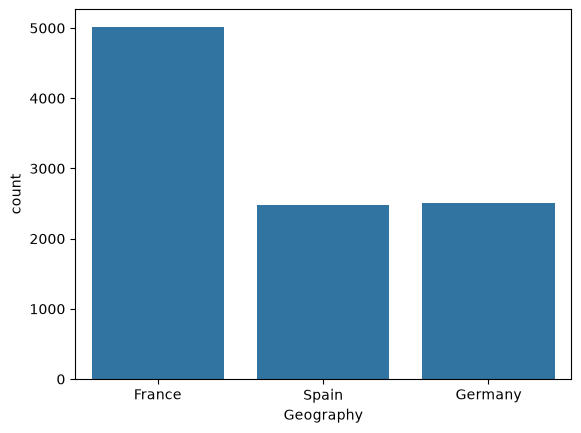

In [10]:
sns.countplot(x="Geography", data=df)
plt.show()

In [11]:
churn_geo=df.groupby('Geography')["Exited"].mean().reset_index()

In [12]:
churn_geo["Exited"]=churn_geo["Exited"]*100

In [13]:
churn_geo

,Geography,Exited
0,France,16.154767
1,Germany,32.443204
2,Spain,16.673395


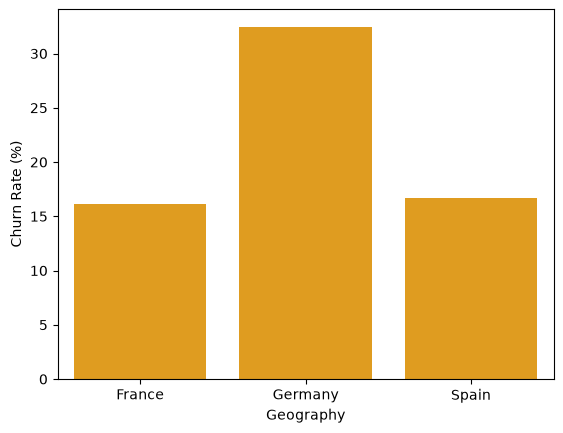

In [14]:
sns.barplot(churn_geo, x="Geography",y="Exited",color="orange")
plt.xlabel("Geography")
plt.ylabel("Churn Rate (%)")
plt.show()

In [15]:
df["Gender"].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

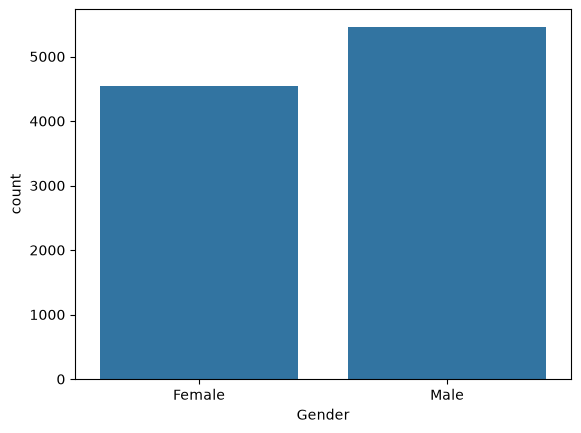

In [16]:
sns.countplot(x=df["Gender"],data=df)
plt.show()

In [17]:
churn_gen=df.groupby('Gender')["Exited"].mean().reset_index()

In [18]:
churn_gen["Exited"]=churn_gen["Exited"]*100


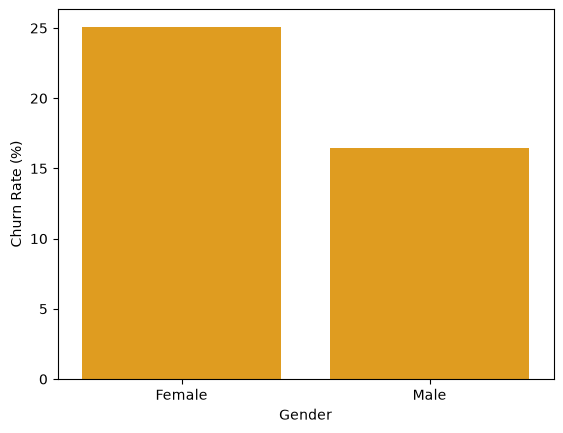

In [19]:
sns.barplot(churn_gen, x="Gender",y="Exited",color="orange")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.show()    

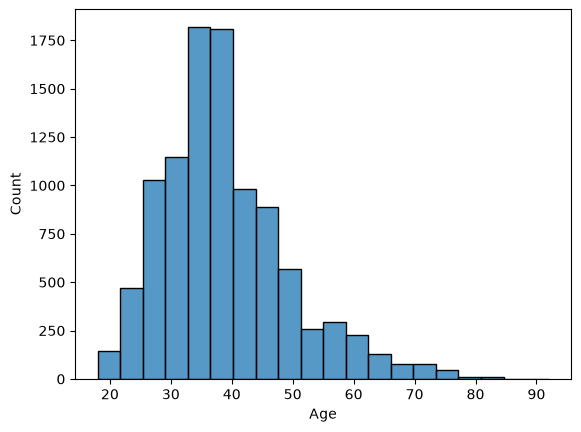

In [20]:
sns.histplot(df["Age"], bins=20)
plt.show()

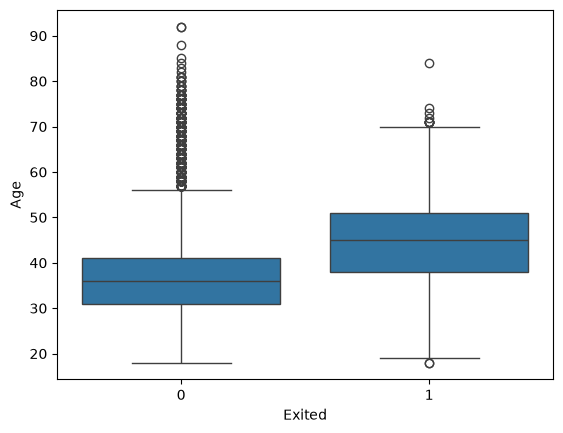

In [21]:
sns.boxplot(data=df, x="Exited", y="Age")
plt.show()

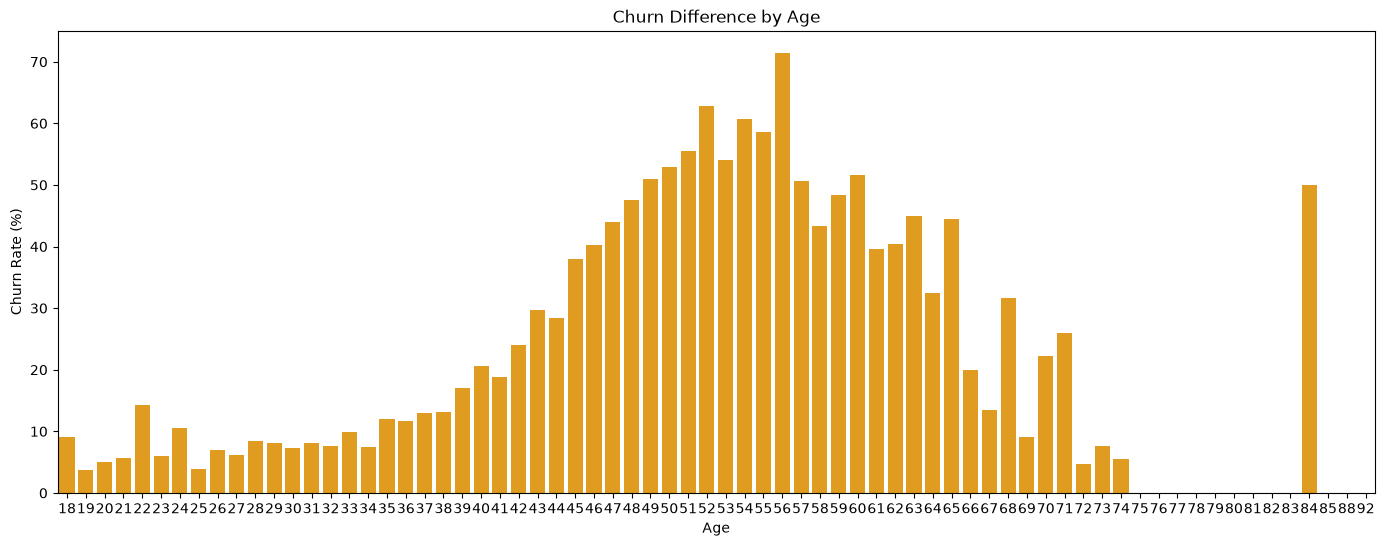

In [22]:
churn_age = df.groupby('Age')["Exited"].mean().reset_index()

churn_age["Exited"] = churn_age["Exited"] * 100

plt.figure(figsize=(17,6))
sns.barplot(data=churn_age, x="Age", y="Exited", color="orange")

plt.xlabel("Age")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Difference by Age")

plt.show()

In [98]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "65+"
    ]
)

In [99]:
age_churn = df.groupby("AgeGroup", observed=False)["Exited"].mean() * 100

age_churn

AgeGroup
18-25     7.528642
26-35     8.498024
36-45    19.619914
46-55    50.572082
56-65    48.320896
65+      13.257576
Name: Exited, dtype: float64

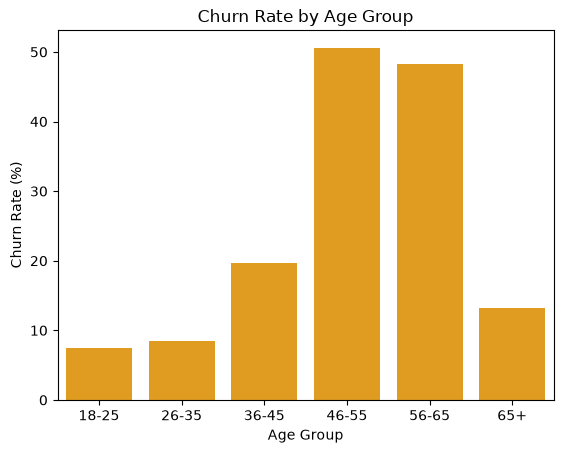

In [100]:
sns.barplot(x=age_churn.index, y=age_churn.values, color="orange")

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.show()

In [23]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


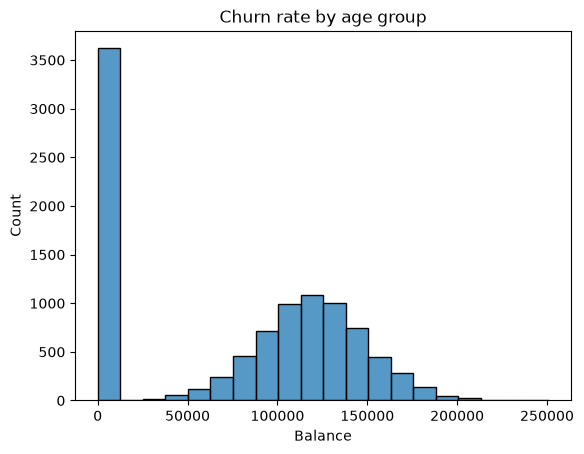

In [24]:
sns.histplot(df["Balance"], bins=20)
plt.title("Churn rate by age group")
plt.show()

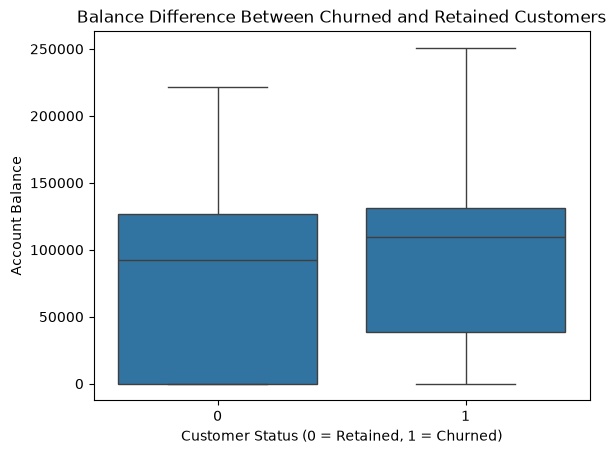

In [25]:
sns.boxplot(data=df, x="Exited", y="Balance")

plt.xlabel("Customer Status (0 = Retained, 1 = Churned)")
plt.ylabel("Account Balance")
plt.title("Balance Difference Between Churned and Retained Customers")

plt.show()

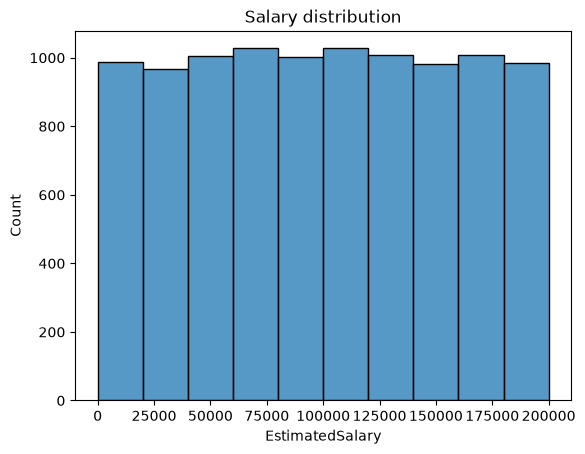

In [26]:
sns.histplot(df["EstimatedSalary"], bins=10)
plt.title("Salary distribution")
plt.show()

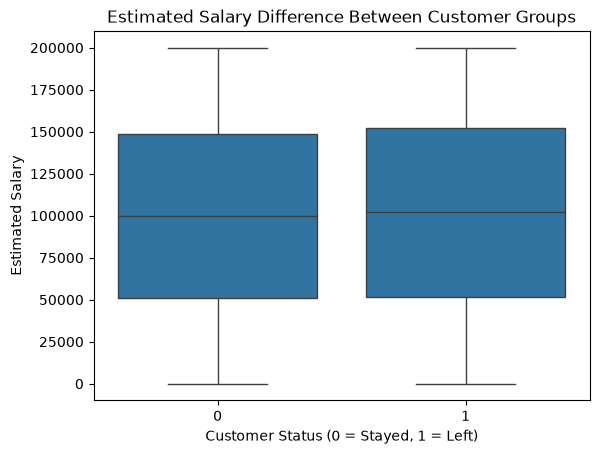

In [27]:
sns.boxplot(data=df, x="Exited", y="EstimatedSalary")
plt.xlabel("Customer Status (0 = Stayed, 1 = Left)")
plt.ylabel("Estimated Salary")
plt.title("Estimated Salary Difference Between Customer Groups")
plt.show()

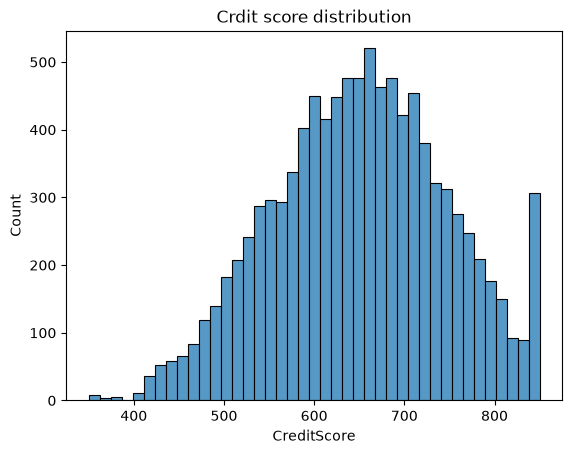

In [28]:
sns.histplot(data=df,x=df["CreditScore"])
plt.title("Crdit score distribution")
plt.show()

In [29]:
def categorize_credit(score):
    if score < 580:
        return "Low"
    elif score < 670:
        return "Fair"
    elif score < 740:
        return "Good"
    elif score < 800:
        return "Very Good"
    else:
        return "Excellent"

In [30]:
df["CredscoreCategory"]=df["CreditScore"].apply(categorize_credit)

In [31]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,CredscoreCategory
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,Fair
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,Fair
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,Low
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,Good
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,Excellent


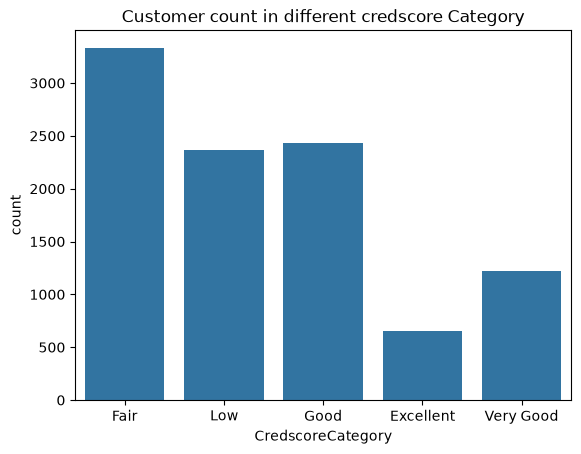

In [32]:
sns.countplot(data=df,x="CredscoreCategory")
plt.title("Customer count in different credscore Category")
plt.show()

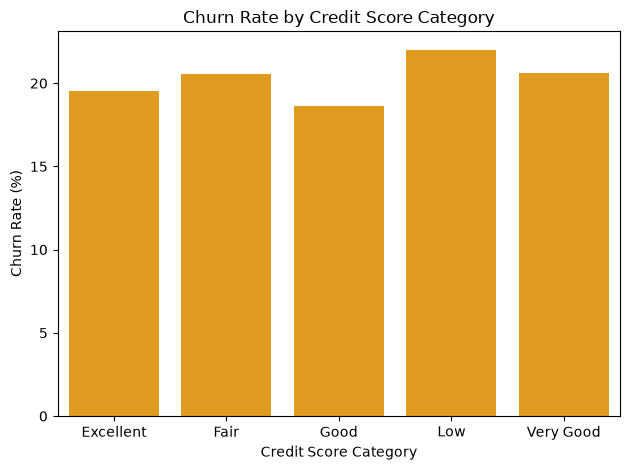

In [33]:

churn_credit = df.groupby("CredscoreCategory")["Exited"].mean().reset_index()


churn_credit["Exited"] = churn_credit["Exited"] * 100


sns.barplot(data=churn_credit, x="CredscoreCategory", y="Exited", color="orange")

plt.xlabel("Credit Score Category")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Credit Score Category")
plt.tight_layout()
plt.show()

In [34]:
df["Tenure"].value_counts()

Tenure
2     1048
1     1035
7     1028
8     1025
5     1012
3     1009
4      989
9      984
6      967
10     490
0      413
Name: count, dtype: int64

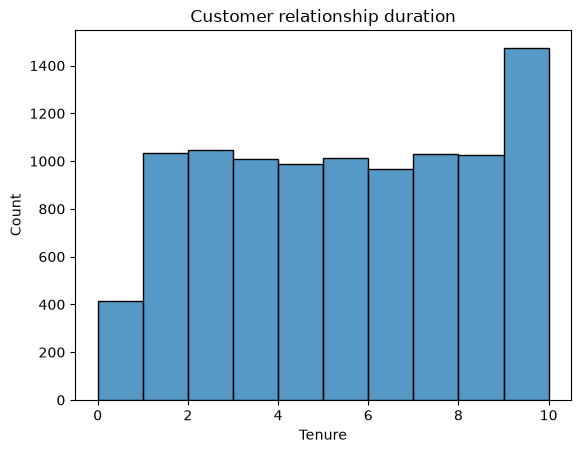

In [35]:
sns.histplot(data=df,x="Tenure",bins=10)
plt.title("Customer relationship duration")
plt.show()

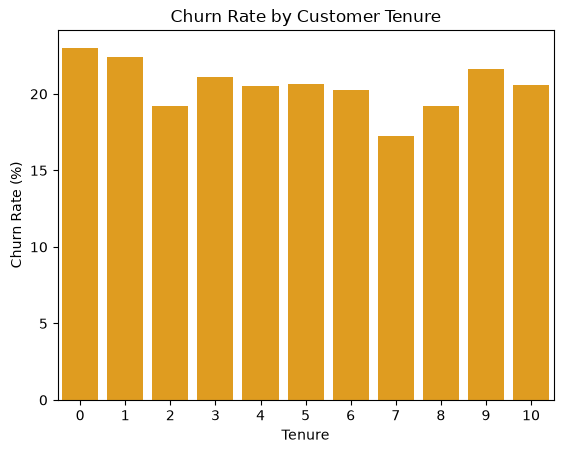

In [36]:
churn_ten = df.groupby("Tenure")["Exited"].mean().reset_index()


churn_ten["Exited"] = churn_ten["Exited"] * 100


sns.barplot(data=churn_ten, x="Tenure", y="Exited", color="orange")

plt.xlabel("Tenure")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Customer Tenure")


plt.show()

In [45]:
df['NumOfProducts'].value_counts()

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

<Axes: xlabel='NumOfProducts', ylabel='count'>

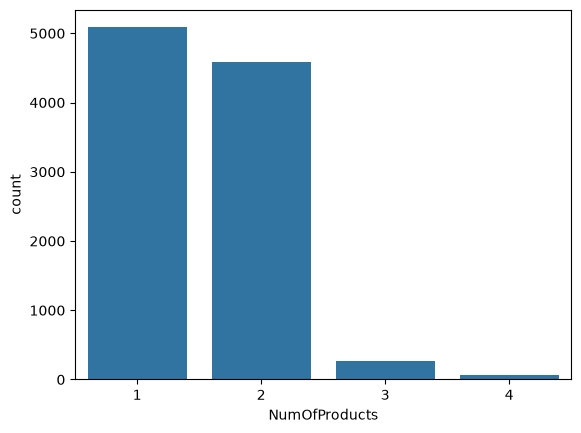

In [46]:
sns.countplot(data=df, x='NumOfProducts')

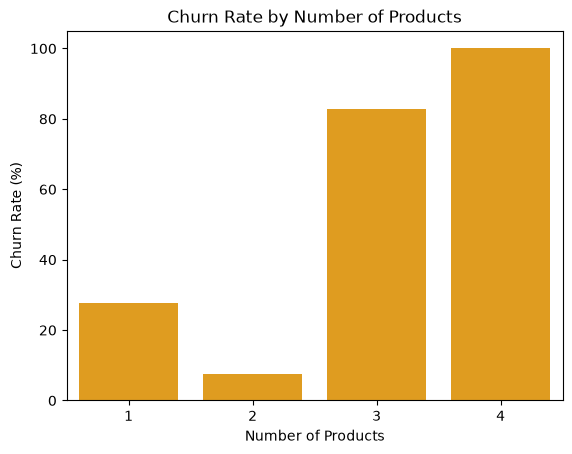

In [97]:
churn_product = df.groupby("NumOfProducts")["Exited"].mean().reset_index()

churn_product["Exited"] *= 100

sns.barplot(
    data=churn_product,
    x="NumOfProducts",
    y="Exited",
    color="orange"
)

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.show()

In [51]:
df["HasCrCard"].value_counts()

HasCrCard
1    7055
0    2945
Name: count, dtype: int64

<Axes: xlabel='HasCrCard', ylabel='count'>

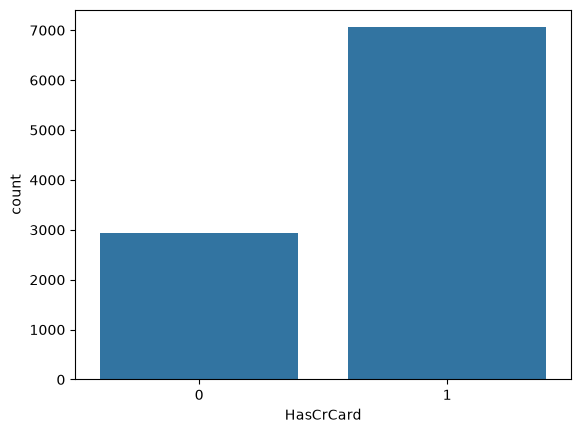

In [52]:
sns.countplot(data=df, x="HasCrCard")

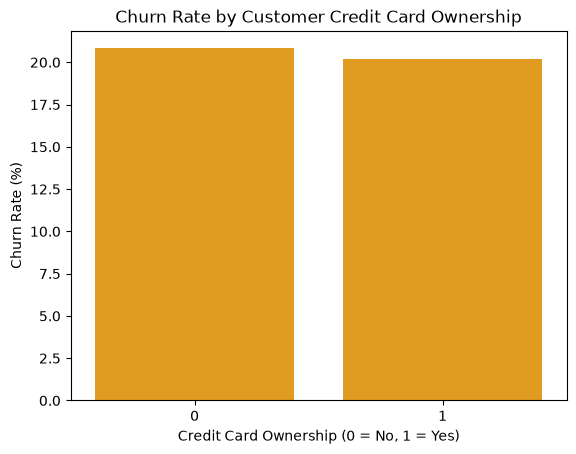

In [65]:
churn_cr = df.groupby("HasCrCard")["Exited"].mean().reset_index()

churn_cr["Exited"] = churn_cr["Exited"] * 100

sns.barplot(data=churn_cr, x="HasCrCard", y="Exited", color="orange")

plt.xlabel("Credit Card Ownership (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Customer Credit Card Ownership")

plt.show()

In [66]:
df["IsActiveMember"].value_counts()

IsActiveMember
1    5151
0    4849
Name: count, dtype: int64

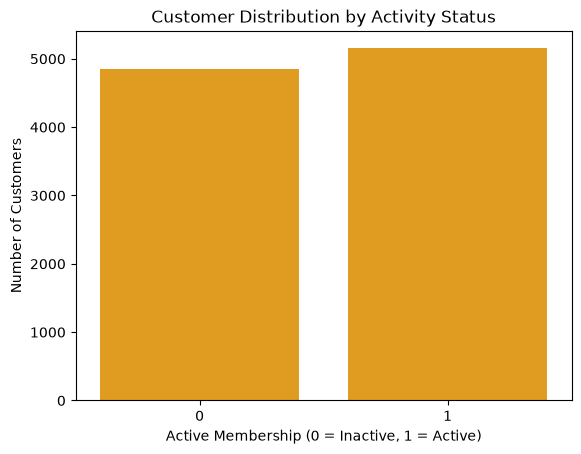

In [67]:
sns.countplot(data=df, x="IsActiveMember", color="orange")

plt.xlabel("Active Membership (0 = Inactive, 1 = Active)")
plt.ylabel("Number of Customers")
plt.title("Customer Distribution by Activity Status")

plt.show()

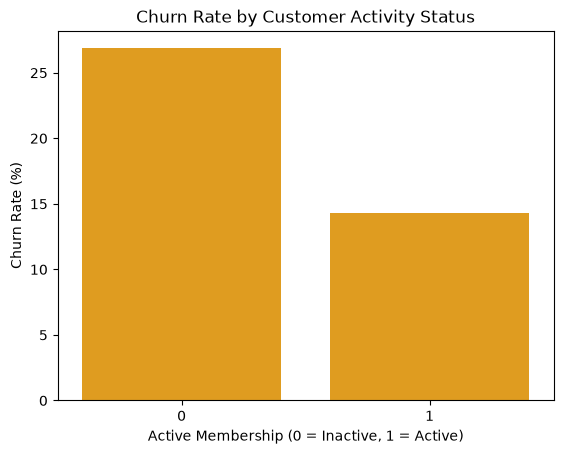

In [70]:
churn_active = df.groupby("IsActiveMember")["Exited"].mean().reset_index()

churn_active["Exited"] = churn_active["Exited"] * 100

sns.barplot(data=churn_active, x="IsActiveMember", y="Exited", color="orange")

plt.xlabel("Active Membership (0 = Inactive, 1 = Active)")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Customer Activity Status")

plt.show()

In [ ]:
#Customer Retention 
df.groupby("IsActiveMember")["Exited"].apply(
    lambda x: (x == 0).mean() * 100
).reset_index()

,IsActiveMember,Exited
0,0,73.149103
1,1,85.730926


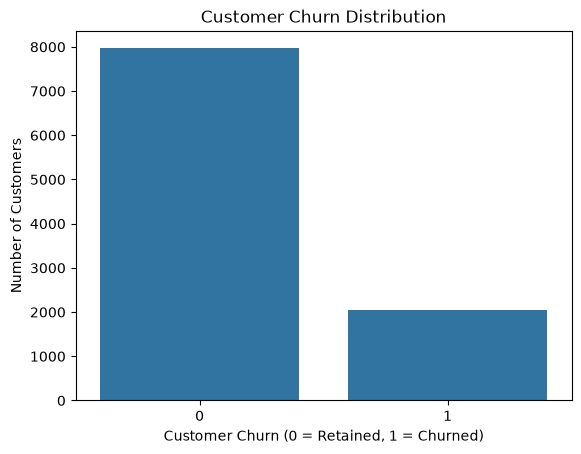

In [82]:
sns.countplot(data=df,x="Exited")
plt.xlabel("Customer Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.title("Customer Churn Distribution")

plt.show()


In [86]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,CredscoreCategory
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,Fair
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,Fair
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,Low
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,Good
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,Excellent


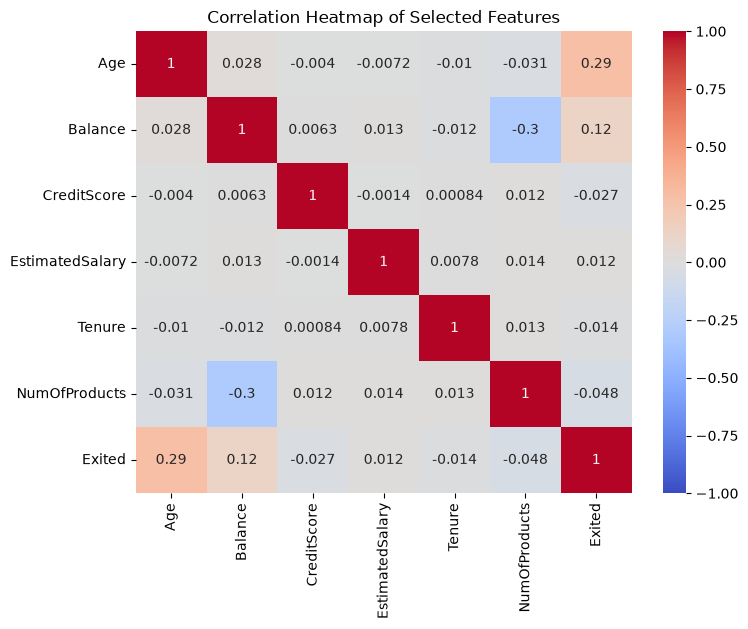

In [90]:
corr = df[["Age", "Balance" ,"CreditScore","EstimatedSalary" ,"Tenure" ,"NumOfProducts","Exited"]].corr()


plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Selected Features")
plt.show()

In [95]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate Customer IDs:", df["CustomerId"].duplicated().sum())

print("Unique customers:", df["CustomerId"].nunique())

Duplicate rows: 0
Duplicate Customer IDs: 0
Unique customers: 10000


In [96]:
zero_balance = (df["Balance"] == 0).sum()

print("Zero balance customers:", zero_balance)
print("Percentage:", zero_balance / len(df) * 100)

Zero balance customers: 3617
Percentage: 36.17


In [ ]:
#consolidated comparison
profile = df.groupby("Exited")[
    [
        "Age",
        "Balance",
        "EstimatedSalary",
        "CreditScore",
        "NumOfProducts",
        "Tenure"
    ]
].mean().T

profile.columns = ["Retained", "Churned"]

profile

,Retained,Churned
Age,37.408389,44.837997
Balance,72745.296779,91108.539337
EstimatedSalary,99738.391772,101465.677531
CreditScore,651.853196,645.351497
NumOfProducts,1.544267,1.475209
Tenure,5.033279,4.932744


**Customer Value and Churn Risk Matrix Analysis**

In [106]:
median_balance=df["Balance"].median()
print("Median Balance:", median_balance)

Median Balance: 97198.54000000001


In [109]:
df['Customer_value']=np.where(df["Balance"]>=median_balance,"High_value","low_value")


In [110]:
df["RiskStatus"] = df["Exited"].map({
    0: "Low Risk",
    1: "High Risk"
})

In [113]:
df["CustomerSegment"] = (
    df["Customer_value"] + " - " + df["RiskStatus"]
)


In [114]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,CredscoreCategory,AgeGroup,Customer_value,RiskStatus,CustomerSegment
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,Fair,36-45,low_value,High Risk,low_value - High Risk
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,Fair,36-45,low_value,Low Risk,low_value - Low Risk
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,Low,36-45,High_value,High Risk,High_value - High Risk
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,Good,36-45,low_value,Low Risk,low_value - Low Risk
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,Excellent,36-45,High_value,Low Risk,High_value - Low Risk


In [115]:
segment_counts = df["CustomerSegment"].value_counts()

print(segment_counts)

CustomerSegment
low_value - Low Risk      4212
High_value - Low Risk     3751
High_value - High Risk    1249
low_value - High Risk      788
Name: count, dtype: int64


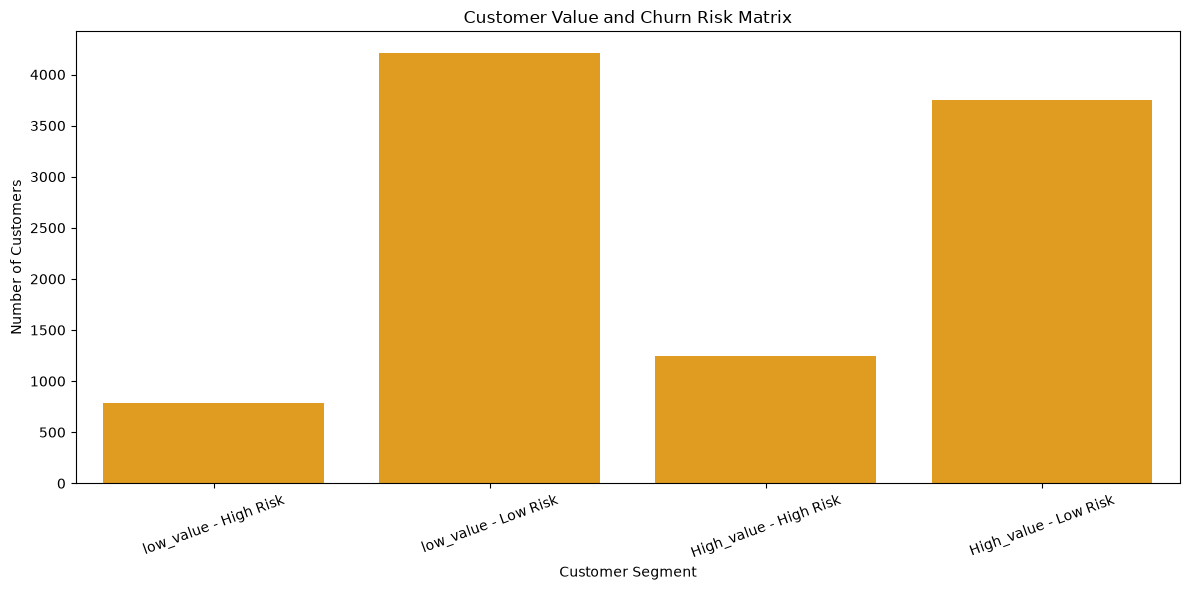

In [118]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="CustomerSegment",
    color="orange"
)

plt.title("Customer Value and Churn Risk Matrix")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()